In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import Perceptron  # Used for simple linear classification tasks.

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tensorflow.keras.models import Sequential  # Sequential lets you build a neural network layer-by-layer in Keras.

from tensorflow.keras.layers import Dense       # Dense makes the final predictions
from tensorflow.keras.layers import Conv2D     # Conv2D extracts features
from tensorflow.keras.layers import Flatten    # Flatten reshapes them

from tensorflow.keras.layers import MaxPooling2D  # MaxPooling2D reduces size
from tensorflow.keras.layers import Dropout        # Dropout prevents overfitting

In [6]:
df=pd.read_csv("train.csv")
df_test=pd.read_csv("test.csv")

In [13]:
df

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41995,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41996,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41997,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41998,6,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [14]:
df.info()
df.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Columns: 785 entries, label to pixel783
dtypes: int64(785)
memory usage: 251.5 MB


(42000, 785)

In [31]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

# Separate features and labels
X = df.drop("label", axis=1).values
y = df["label"].values

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Normalize
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Reshape
X_train_img = X_train.reshape(-1, 28, 28)
X_test_img = X_test.reshape(-1, 28, 28)

# One-hot encode labels
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

In [32]:
X_train_img

array([[[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       ...,

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0.

In [33]:
from tensorflow.keras.utils import to_categorical

y_train_cat = to_categorical(y_train, 10)

using perceptron-


In [34]:
perceptron = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(10, activation="softmax")
])

In [35]:
perceptron.compile(
    optimizer="sgd",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [36]:
perceptron.compile(
    optimizer="sgd",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_percp = perceptron.fit(
    X_train_img,
    y_train_cat,
    epochs=5,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/5
945/945 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7703 - loss: 0.9996 - val_accuracy: 0.8560 - val_loss: 0.6254
Epoch 2/5
945/945 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8678 - loss: 0.5504 - val_accuracy: 0.8774 - val_loss: 0.4961
Epoch 3/5
945/945 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8811 - loss: 0.4688 - val_accuracy: 0.8872 - val_loss: 0.4405
Epoch 4/5
945/945 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8881 - loss: 0.4290 - val_accuracy: 0.8914 - val_loss: 0.4113
Epoch 5/5
945/945 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8928 - loss: 0.4041 - val_accuracy: 0.8943 - val_loss: 0.3915


In [37]:
test_loss, test_accuracy = perceptron.evaluate(
    X_test_img, y_test_cat, verbose=0
)

print("Test Accuracy:", test_accuracy * 100, "%")
print("Test Loss:", test_loss)

Test Accuracy: 89.09524083137512 %
Test Loss: 0.4000207781791687


using Ann


In [38]:
  # ANN
ann = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

In [39]:
ann.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [40]:
history_ann = ann.fit(
    X_train_img,
    y_train_cat,
    epochs=5,
    batch_size=32,
    validation_data=(X_test_img, y_test_cat),
    verbose=1
)

Epoch 1/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.9108 - loss: 0.3086 - val_accuracy: 0.9451 - val_loss: 0.1837
Epoch 2/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9614 - loss: 0.1285 - val_accuracy: 0.9598 - val_loss: 0.1391
Epoch 3/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9719 - loss: 0.0885 - val_accuracy: 0.9645 - val_loss: 0.1217
Epoch 4/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9797 - loss: 0.0637 - val_accuracy: 0.9633 - val_loss: 0.1273
Epoch 5/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9846 - loss: 0.0476 - val_accuracy: 0.9660 - val_loss: 0.1225


In [41]:
acc_ann = ann.evaluate(
    X_test_img, y_test_cat, verbose=0
)[1]

print("ANN Test Accuracy:", acc_ann * 100, "%")

ANN Test Accuracy: 96.59523963928223 %


cnn-

In [42]:
X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

In [43]:
cnn = Sequential([
    Conv2D(32, kernel_size=(3, 3), activation="relu", input_shape=(28, 28, 1)),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(64, kernel_size=(3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(10, activation="softmax")
])

In [44]:
cnn.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [45]:
history_cnn = cnn.fit(
    X_train_img,
    y_train_cat,
    epochs=5,
    batch_size=32,
    validation_data=(X_test_img, y_test_cat),
    verbose=1
)

Epoch 1/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 31s 28ms/step - accuracy: 0.9124 - loss: 0.2826 - val_accuracy: 0.9780 - val_loss: 0.0710
Epoch 2/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 31s 29ms/step - accuracy: 0.9690 - loss: 0.1032 - val_accuracy: 0.9850 - val_loss: 0.0496
Epoch 3/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 41s 30ms/step - accuracy: 0.9787 - loss: 0.0716 - val_accuracy: 0.9870 - val_loss: 0.0440
Epoch 4/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 29s 27ms/step - accuracy: 0.9832 - loss: 0.0563 - val_accuracy: 0.9863 - val_loss: 0.0441
Epoch 5/5
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 32s 31ms/step - accuracy: 0.9860 - loss: 0.0473 - val_accuracy: 0.9899 - val_loss: 0.0353


In [46]:
acc_cnn = cnn.evaluate(
    X_test_img, y_test_cat, verbose=0
)[1]

print("CNN Test Accuracy:", acc_cnn * 100, "%")

CNN Test Accuracy: 98.98809790611267 %


In [47]:
def plot_training(history, title):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label="Train")
    plt.plot(history.history['val_accuracy'], label="Val")
    plt.title(f"{title} Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label="Train")
    plt.plot(history.history['val_loss'], label="Val")
    plt.title(f"{title} Loss")
    plt.legend()

    plt.show()

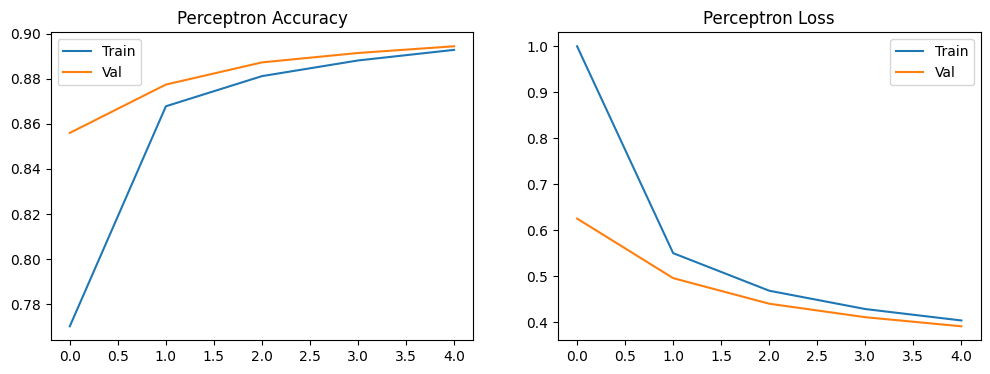

In [48]:
plot_training(history_percp, "Perceptron")

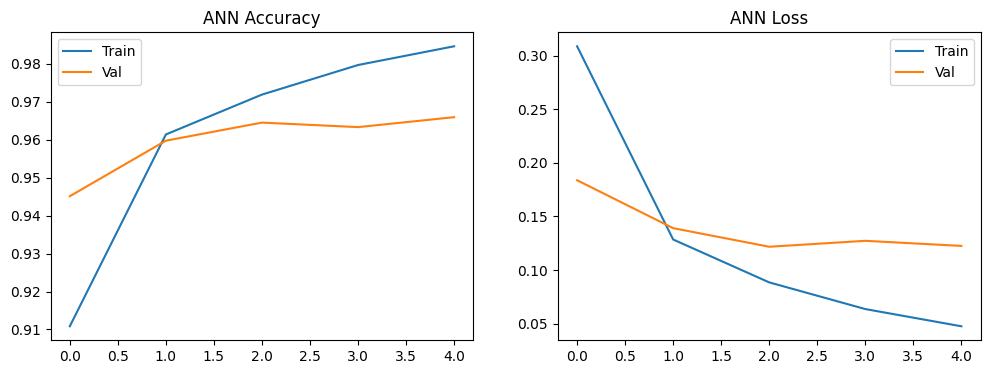

In [49]:
plot_training(history_ann, "ANN")

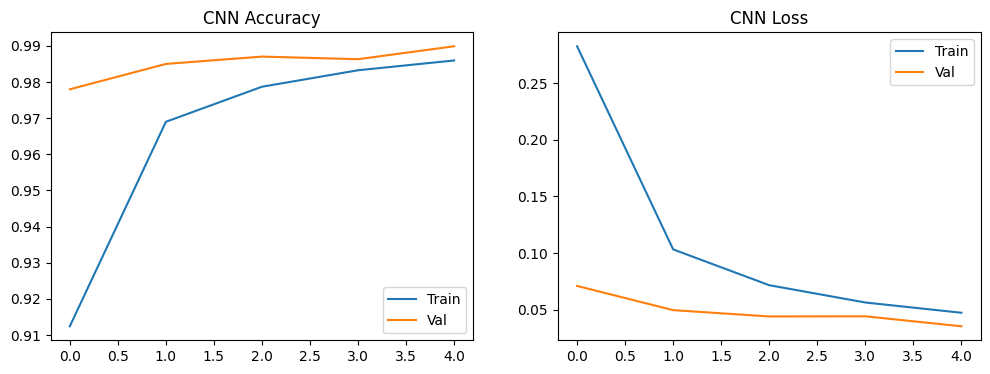

In [50]:
plot_training(history_cnn, "CNN")

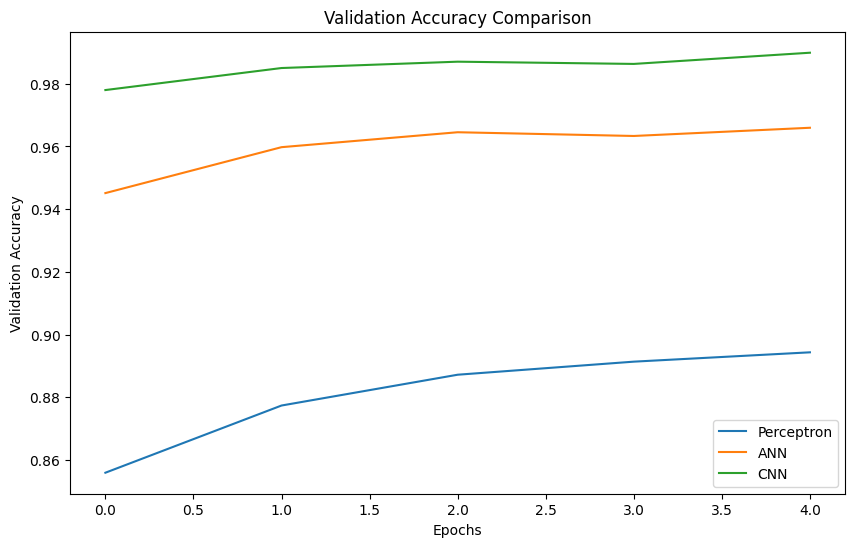

In [51]:
plt.figure(figsize=(10, 6))

plt.plot(history_percp.history['val_accuracy'], label="Perceptron")
plt.plot(history_ann.history['val_accuracy'], label="ANN")
plt.plot(history_cnn.history['val_accuracy'], label="CNN")

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.show()

In [56]:
def show_side_by_side(models, model_names, X, X_cnn, y_true, n=5):
    idxs = np.random.choice(len(X), n, replace=False)

    plt.figure(figsize=(15, 6))

    for i, idx in enumerate(idxs):
        plt.subplot(2, n, i + 1)
        plt.imshow(X[idx].reshape(28, 28), cmap="gray")
        plt.axis("off")
        plt.title(f"True: {y_true[idx]}")

        preds = [
            np.argmax(
                model.predict(
                    X_cnn[idx].reshape(1, 28, 28, 1)
                    if name == "CNN"
                    else X[idx].reshape(1, 28, 28)
                ),
                axis=1
            )[0]
            for model, name in zip(models, model_names)
        ]

        plt.subplot(2, n, n + i + 1)
        plt.axis("off")
        plt.title(
            "\n".join(
                f"{name}: {p}"
                for name, p in zip(model_names, preds)
            )
        )

    plt.tight_layout()
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step


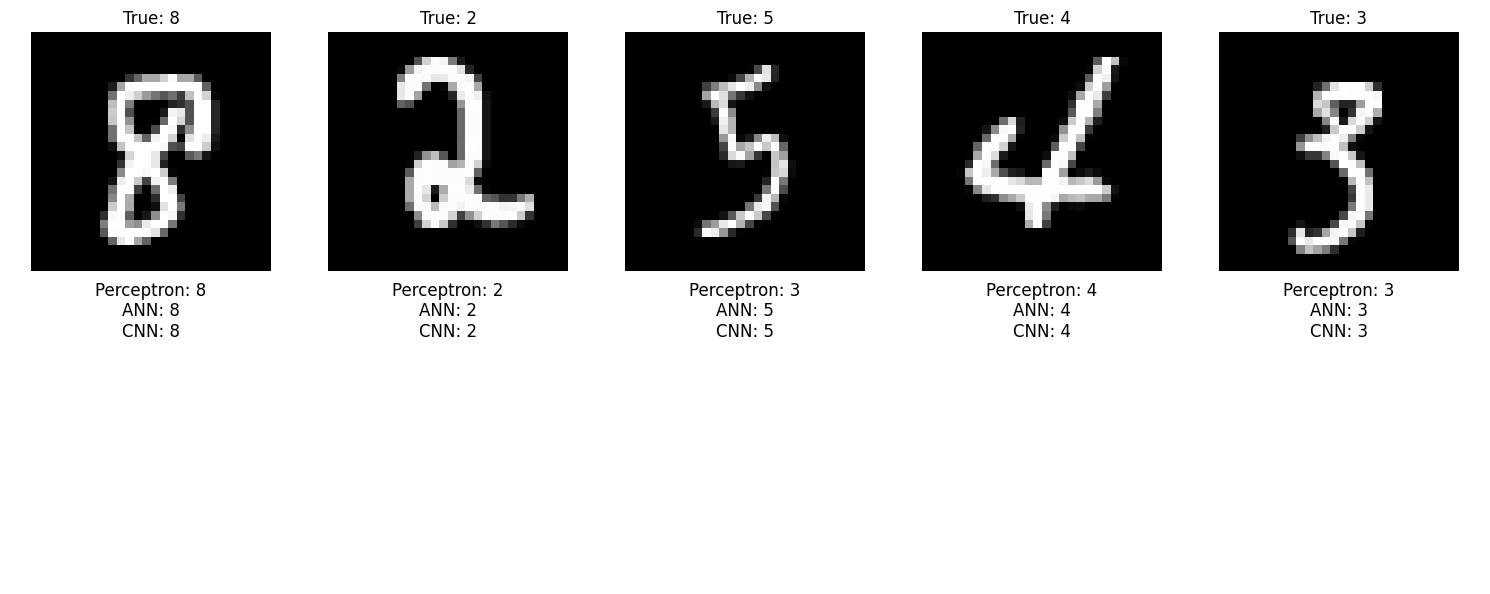

In [57]:
show_side_by_side(
    [perceptron, ann, cnn],
    ["Perceptron", "ANN", "CNN"],
    X_test,
    X_test_cnn,
    y_test,
    n=5
)

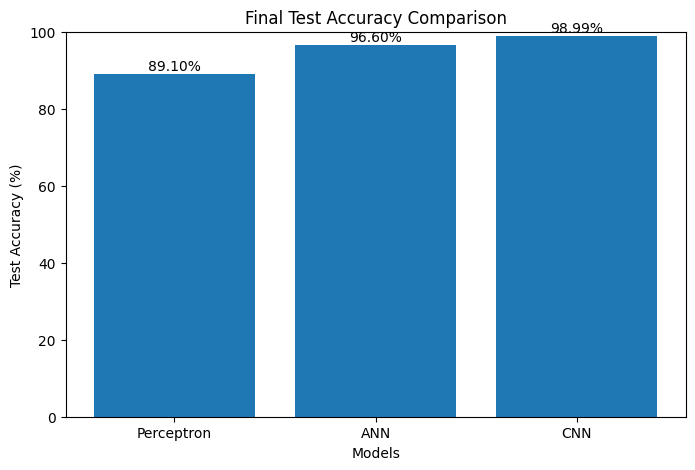

In [59]:
# Evaluate final test accuracy of all three models

acc_perceptron = perceptron.evaluate(
    X_test_img, y_test_cat, verbose=0
)[1]

acc_ann = ann.evaluate(
    X_test_img, y_test_cat, verbose=0
)[1]

# Using X_test_img since the CNN was trained on 3D (28, 28) image arrays
acc_cnn = cnn.evaluate(
    X_test_img, y_test_cat, verbose=0
)[1]

# Convert accuracy to percentage
accuracies = [
    acc_perceptron * 100,
    acc_ann * 100,
    acc_cnn * 100
]

model_names = ["Perceptron", "ANN", "CNN"]

# Plot bar diagram
plt.figure(figsize=(8, 5))
bars = plt.bar(model_names, accuracies)

plt.title("Final Test Accuracy Comparison")
plt.xlabel("Models")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)

# Show accuracy values above bars
for bar, acc in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{acc:.2f}%",
        ha="center",
        va="bottom"
    )

plt.show()